In [6]:
%load_ext autoreload
%autoreload 2

# Static configuration

## Device

In [7]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

first_layout_qubit = 43
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

## Lattice

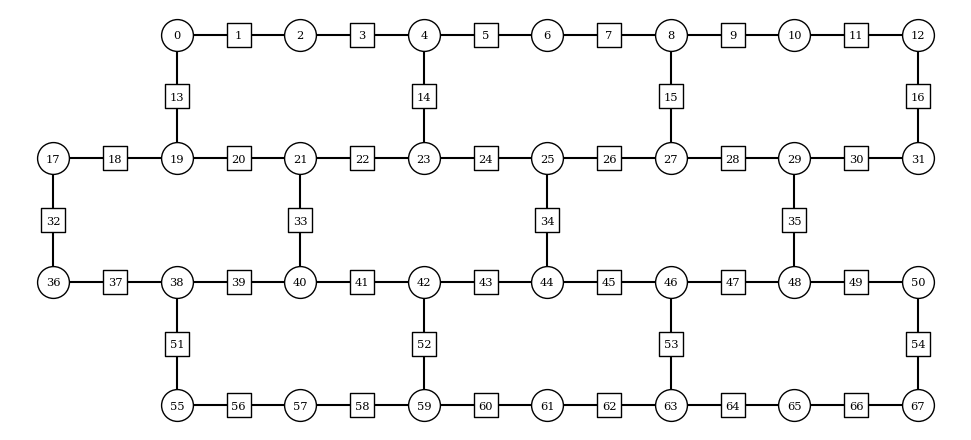

In [8]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

## Options

In [9]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB

lattice_dims_arr = [(3, 3)]
J_arr = [5]
# g_arr = [0.01, 0.05, 0.1, 0.15, 0.2]
h_arr = [5]
lamb_arr = [1]
g_arr = [10]

x_basis = False

fractional_gates = False

# strings_arr = [[6, 7, 8, 16, 26, 25, 24, 34, 43, 44, 45, 54, 64, 63, 62, 72, 81, 82, 83, 92, 102, 101, 100]]
strings_arr = [[4, 14, 24, 34, 45, 53, 63]]
# strings_arr = [[12, 16, 30, 35, 47, 53, 64, 72, 81, 90, 98, 109, 115, 127, 131]]
# strings_arr = [[4, 14, 24]]

final_time = 2
dt = 0.1
steps = 35

max_layers = 50
adjust_depth = True

shots = 75000

odr = True
flip_threshold = None

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

## Circuits

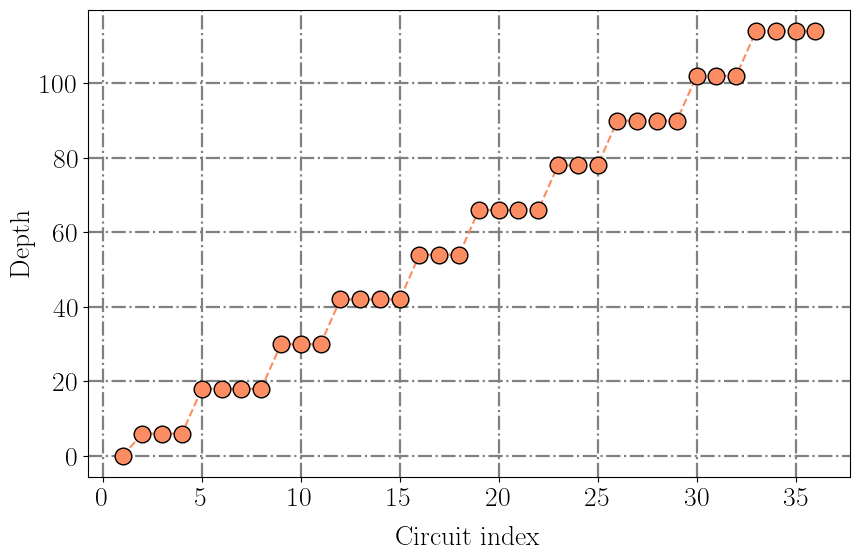

In [10]:
from z2hex.circs import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import os

optimization_level = 3

circuits = [] # circuits[dims][Jhλg][t]
if odr: odr_circuits = []
observable_generating_funcs = [] # observable_generating_funcs[dims][i]
postselection_operators_funcs = [] # postselection_operators_funcs[dims][i]
extra_options = [] # extra_options[dims][Jhλg]

for (px, py), string_arr in zip(lattice_dims_arr, strings_arr):
    this_circuits = []
    if odr: this_odr_circuits = []
    this_extra_options = []
    lattice = HeavyHexLattice(px, py)
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        circuits_filepath = os.path.join(circ_folder_path, f"z2hex_string_quench_circs_{device}_px_{px}_py_{py}_maxt_{final_time}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.qpy")
        circs_args = (lattice, J, h, lamb, string_arr, final_time, dt, steps, backend, optimization_level, g, first_layout_qubit, x_basis, True, False)
        physical_circuits = string_quench_simulation_circuits_dt(*circs_args)
        this_circuits.append(physical_circuits)
        this_extra_options.append({"backend": device, "plaquette_width": px, "plaquette_height": py, "J": J, "h": h, "λ":lamb, "g": g, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {}))
        if odr:
            odr_func_args = (lattice, J, h, lamb, final_time, dt, steps, backend, g, string_arr, first_layout_qubit, x_basis)
            this_odr_circuits.append(odr_compuncomp_circuits_dt(*odr_func_args))
    circuits.append(this_circuits)
    if odr: odr_circuits.append(this_odr_circuits)
    observable_generating_funcs.append([(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))])
    postselection_operators_funcs.append(lambda nqubits: postselection_operators(lattice, x_basis))
    extra_options.append(this_extra_options)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits[0][0])

## Hardware execution

In [20]:
from utils.postselection import execute_postselected_sampler_batch
from itertools import product

jobs = [] # jobs[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_jobs = []
    for Ji, hi, lambi, gi in product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr))):
        params_ind = gi + lambi*len(g_arr) + hi*len(g_arr)*len(lamb_arr) + Ji*len(g_arr)*len(lamb_arr)*len(g_arr)
        if odr:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], odr_circuits=odr_circuits[i][params_ind], extra_options=extra_options[i][params_ind], job_db=job_db)
        else:
            this_jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits[i][params_ind], postselection_operators_funcs[i], observable_generating_funcs[i], extra_options=extra_options[i][params_ind], job_db=job_db)
        this_dims_jobs.append(this_jobs)
    jobs.append(this_dims_jobs)

## Load jobs

In [11]:
from utils.postselection import load_postselected_jobs
from itertools import product

observables = [] # jobs[dims][Jhλg][t]
samples_dicts = [] # samples_dicts[dims][Jhλg][t]
postselected_samples_dicts = [] # postselected_samples_dicts[dims][Jhλg][t]

for i, (px, py) in enumerate(lattice_dims_arr):
    this_dims_observables = []
    this_dims_samples_dicts = []
    this_dims_postselected_samples_dicts = []
    for j, (Ji, hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        clean_extra_options = extra_options[i][j].copy()
        if odr:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, odr_circuits=odr_circuits[i][j], max_shots=shots)
        else:
            this_observables, this_samples_dicts, this_postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits[i][j], postselection_operators_funcs[i], observable_generating_funcs[i], clean_extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, max_shots=shots)
        this_dims_observables.append(this_observables)
        this_dims_samples_dicts.append(this_samples_dicts)
        this_dims_postselected_samples_dicts.append(this_postselected_samples_dicts)
    observables.append(this_dims_observables)
    samples_dicts.append(this_dims_samples_dicts)
    postselected_samples_dicts.append(this_dims_postselected_samples_dicts)

## Plot

In [12]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

for i, (px, py) in enumerate(lattice_dims_arr):
    for j, (Ji, Hi, lambi, gi) in enumerate(product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr)))):
        postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
        local_obs_anim((1 - observables[i][j][0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
        local_obs_anim((1 - observables[i][j][1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
        local_obs_anim((1 - observables[i][j][2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
        local_obs_anim((1 - observables[i][j][3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

# Reproducing 1D dynamics

## Device

In [1]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

first_layout_qubit = 43
eplg_absolute = 1e-2

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

## Lattice

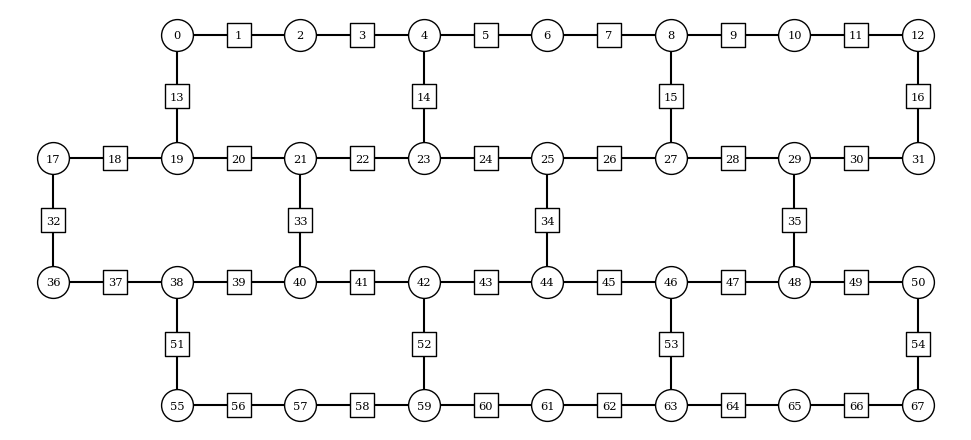

In [2]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

HeavyHexLattice(plaquette_width, plaquette_height).plot_lattice(number_qubits=True)

## Options

In [3]:
from utils.hexec import ExecDB

lattice_dimensions = (3, 3)

J_1d = 1
J_rest = 25
h_1d = 0.05
h_rest = 25
lamb_1d = 0.7
lamb_rest = 0
g = 10

chain_qubits_on_lattice = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 16, 31]
particle_pair_left_position = len(chain_qubits_on_lattice) // 4
particle_pair_length = 1
string_arr = chain_qubits_on_lattice[2*particle_pair_left_position:2*particle_pair_left_position + 2*particle_pair_length + 1]

x_basis = False

final_time = 8
dt = 0.2
steps = 35

shots = 75000

odr = True
flip_threshold = None
fractional_gates = False

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    }
}

execution_database = "z2_hex_jobs_sanity_checks.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

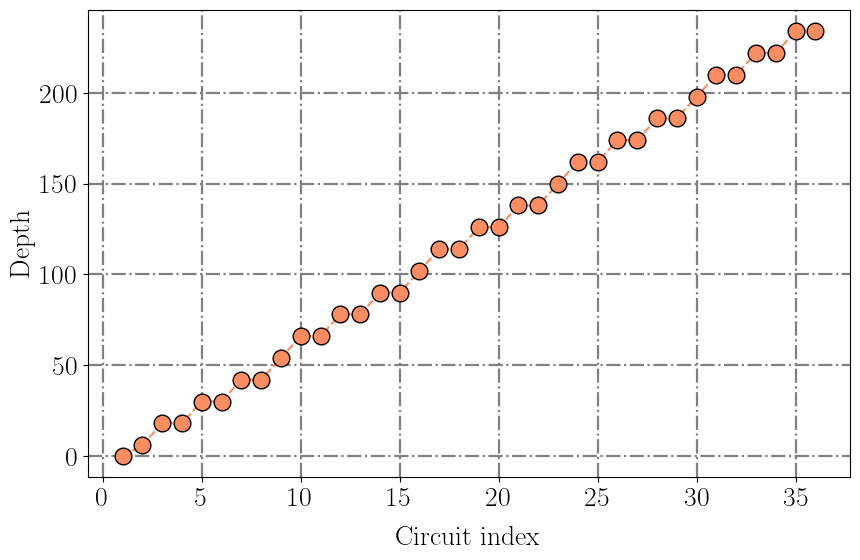

In [4]:
from z2hex.circs2 import string_quench_simulation_circuits_dt, odr_compuncomp_circuits_dt
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.plotting import plot_circuit_arr_depth
from utils.circs import generate_and_save_circs
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

lattice = HeavyHexLattice(*lattice_dimensions)

layout_node_qinds = lattice.coords_to_logical_qb(lattice.node_coords)
layout_gauge_quinds = lattice.coords_to_logical_qb(lattice.edge_coords)

Js = np.full(len(lattice.node_coords), J_rest, dtype=float)
for qbind in chain_qubits_on_lattice[::2]:
    lind = np.where(np.equal(layout_node_qinds, qbind))[0]
    Js[lind] = J_1d
hs = np.full(len(lattice.edge_coords), h_rest, dtype=float)
lambdas = np.full(len(lattice.edge_coords), lamb_rest, dtype=float)
for qbind in chain_qubits_on_lattice[1::2]:
    lind = np.where(np.equal(layout_gauge_quinds, qbind))[0]
    hs[lind] = h_1d
    lambdas[lind] = lamb_1d

optimization_level = 3

circs_args = (lattice, Js, hs, lambdas, string_arr, final_time, dt, steps, backend, optimization_level, g, first_layout_qubit, x_basis, True, False)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dimensions[0], "plaquette_height": lattice_dimensions[1], "J": Js.tolist(), "h": hs.tolist(), "λ":lambdas.tolist(), "g": g, "string_arr": string_arr, "final_time": final_time, "dt": dt, "steps": steps} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    odr_func_args = (lattice, Js, hs, lambdas, final_time, dt, steps, backend, g, string_arr, first_layout_qubit, x_basis)
    odr_circuits = odr_compuncomp_circuits_dt(*odr_func_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)
plot_circuit_arr_depth(circuits)

## Hardware execution

In [ ]:
from utils.postselection import execute_postselected_sampler_batch
from itertools import product

jobs = [] # jobs[t]

if odr:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, odr_circuits=odr_circuits, extra_options=extra_options, job_db=job_db)
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, postselection_operators_funcs, observable_generating_funcs, extra_options=extra_options, job_db=job_db)

NameError: name 'this_dims_jobs' is not defined

## Load jobs

In [5]:
from utils.postselection import load_postselected_jobs
from itertools import product

if odr:
    observables, samples_dicts, postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, odr_circuits=odr_circuits, max_shots=shots)
else:
    observables, samples_dicts, postselected_samples_dicts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, return_samples_dicts=True, return_postselected_samples_dicts=True, max_shots=shots)

## Plots

In [7]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

postselected_odr_filepath = f"z2hex_1drepro_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"z2hex_1drepro_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
odr_filepath = f"z2hex_1drepro_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
raw_filepath = f"z2hex_1drepro_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_J_{J_1d:.04f}_h_{h_1d:.04f}_lamb_{lamb_1d:.04f}_g_{g}_fqb_{first_layout_qubit}_string_{"-".join([str(i) for i in string_arr])}_xbasis_{x_basis}.mp4"
local_obs_anim((1 - observables[0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
local_obs_anim((1 - observables[1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
local_obs_anim((1 - observables[2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
local_obs_anim((1 - observables[3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_3 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

In [10]:
observables[0]

array([[0.99887366, 0.99895761, 0.99547084, ..., 1.00155959, 1.00013477,
        0.99833647],
       [1.00852021, 0.96476644, 0.92144135, ..., 1.01763392, 1.01772604,
        1.02625355],
       [0.92096047, 0.92548097, 0.83541878, ..., 0.97873704, 0.98434749,
        0.96060552],
       ...,
       [0.86508539, 0.68470492,        nan, ..., 0.87882295, 0.84089648,
        0.97159859],
       [0.67860582, 0.59268495, 0.93291201, ..., 0.94029611, 0.95496674,
        1.02409529],
       [0.65671384, 0.52859055, 0.66372447, ..., 0.93053863, 0.96771228,
        1.04920882]])

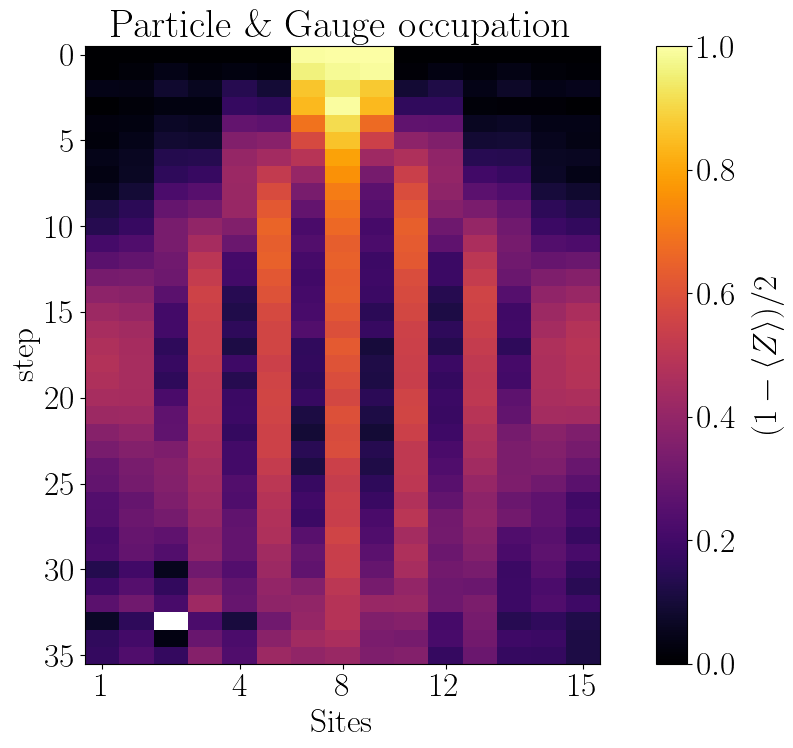

In [18]:
from z2chain.plotting import x_t_plot

x_t_plot((1 - observables[0][:, chain_qubits_on_lattice])/2, [0, 1])

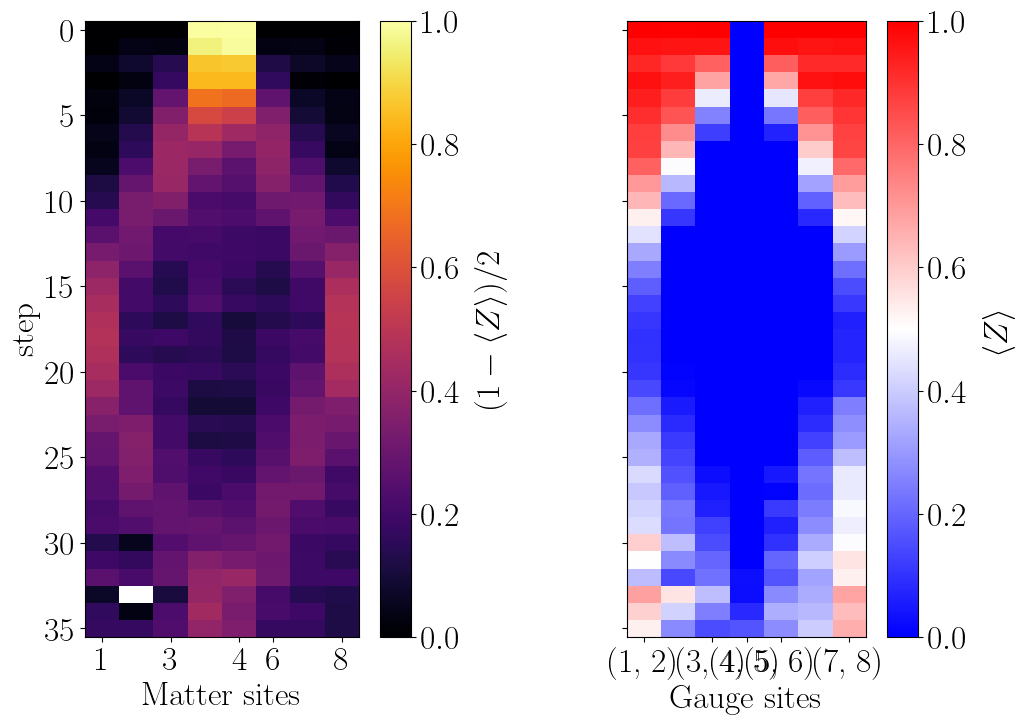

In [20]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observables[0][:, chain_qubits_on_lattice], [0, 1])